# 03 · PSI: fitting a factory's private parameters with inverse optimization

**Where this sits in the chain:** process model → *parameter identification* → dimension reduction → grid/aggregator optimization.

Notebooks 01–02 assumed we **know** the plant's parameters. A grid operator or aggregator usually doesn't: it sees only the factory's **hourly meter data** and the **prices** it faced. Production Scheduling Identification (PSI) asks:

> If the factory schedules production to minimize its electricity cost, which plant parameters make that optimal schedule reproduce the meter data?

This notebook shows the idea on a **2-machine plant whose true parameters we know**, so we can check that inverse optimization recovers them. A single solve takes about a second.

*References:* thesis Ch. 3; R. Lyu et al., "Production Scheduling Identification: An Inverse Optimization Approach for Industrial Load Modeling Using Smart Meter Data," *IEEE Trans. Smart Grid* 16(2), 2025; paper code: [Production-Scheduling-Identification](https://github.com/ruikelyu/Production-Scheduling-Identification).

**Solver note:** the inverse problem is nonconvex (bilinear), so this notebook uses **Gurobi** (`pip install gurobipy` plus a license; academic licenses are free). The size-limited license bundled with `gurobipy` is too small for it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import indflex as fx
from indflex.identify import MSTNParams, simulate, train_psi, nrmse

plt.rcParams["figure.dpi"] = 110

## 1. The plant (a modified STN) and its meter data

Raw material → **machine 1** → buffer → **machine 2** → final product. Machine $i$ draws power $P_{t,i}\in[0,P^{\max}_i]$ and processes $g_i P_{t,i}$ units of material per hour. Buffer $j$ holds between 0 and $S^{\max}_j$, starts the day at $S^0_j$, and must change by $S^{\rm tar}_j$ by the end of the day. The plant schedules its machines to minimize its electricity bill (an LP).

* **Public:** $g_i$ (energy per unit of product is an industry figure), prices, meter data.
* **Private, to be identified:** $\theta = (P^{\max}, S^0, S^{\rm tar}, S^{\max})$.

We pick "true" values, let the plant respond to 10 days of PJM prices (July 2022), and keep only what an outsider would see: the hourly load.

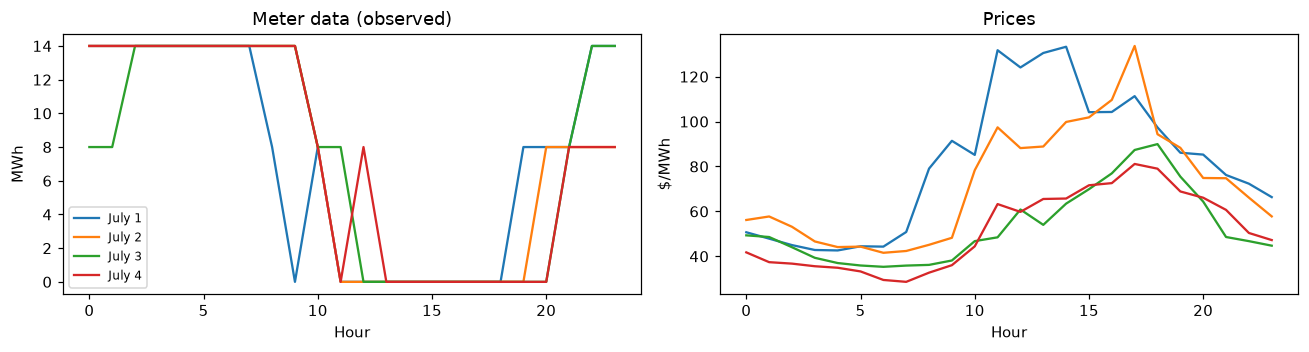

In [2]:
true = MSTNParams(
    g=np.array([0.5, 0.25]),                # public
    p_max=np.array([6.0, 8.0]),             # rated power of machines 1 and 2 (MW)
    s_init=np.array([200.0, 10.0, 0.0]),    # raw material, intermediate, final product
    s_target=np.array([-130.0, 0.0, 30.0]), # daily change: use raw, make 30 units of product
    s_max=np.array([400.0, 20.0, 100.0]),
)
prices = fx.load_prices("2022-07").to_numpy()[:10] / 1000  # $/kWh, 10 training days
meter = simulate(true, prices)                              # what the meter records (MWh)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
for d in range(4):
    axes[0].plot(meter[d], label=f"July {d + 1}")
    axes[1].plot(prices[d] * 1000)
axes[0].set(title="Meter data (observed)", xlabel="Hour", ylabel="MWh"); axes[0].legend(fontsize=8)
axes[1].set(title="Prices", xlabel="Hour", ylabel="$/MWh")
plt.tight_layout(); plt.show()

## 2. Inverse optimization

Given θ, the plant's response $E(\theta, \pi)$ is the solution of an LP. To go backwards, write down **what it means for a schedule to be optimal**, and let θ be a decision variable:

$$
\begin{aligned}
\min_{\theta,\,P,\,S,\,\lambda,\,\mu}\ & \textstyle\sum_t \big(E_t - E^{\rm meter}_t\big)^2 \\
\text{s.t. }& \text{primal feasibility: } P, S \text{ satisfy the mSTN with parameters } \theta \\
& \text{dual feasibility: } \lambda, \mu \text{ satisfy the LP's dual constraints} \\
& \text{strong duality: primal cost} = \text{dual cost} \quad(\text{dual variables} \times \theta \Rightarrow \text{bilinear})
\end{aligned}
$$

Together, the three conditions say that $(P,S)$ is an *optimal* schedule for θ. Two public priors from the paper help: only the raw-material and final-product buffers change over the day, and the rated powers add up to the peak observed load.

For this small plant, **one day of data and one solve are enough** (about 1 s):

In [3]:
from pyomo.contrib.appsi.solvers import Gurobi
from indflex.identify import build_inverse_day
from indflex.identify.psi import theta_of

day = 0  # July 1
m = build_inverse_day(true.g, T=24, dt=1.0, max_load=float(meter.max()))
for t in range(24):
    m.price[t], m.E_obs[t] = prices[day, t], meter[day, t]

opt = Gurobi()
opt.gurobi_options["NonConvex"] = 2  # bilinear strong-duality constraint
opt.config.time_limit = 10
res = opt.solve(m)
theta = theta_of(m)
print(f"{res.termination_condition.name}, squared misfit {m.fit():.2e}")

rows = []
for name, label in [("p_max", "rated power"), ("s_init", "initial level"), ("s_target", "daily change"), ("s_max", "capacity")]:
    for k, (t, e) in enumerate(zip(getattr(true, name), getattr(theta, name))):
        what = f"machine {k + 1}" if name == "p_max" else ["raw material", "intermediate", "final product"][k]
        rows.append({"parameter": f"{label}, {what}", "true": t, "identified": round(e, 2)})
pd.DataFrame(rows).set_index("parameter")

optimal, squared misfit 0.00e+00


,true,identified
parameter,,
"rated power, machine 1",6.0,6.0
"rated power, machine 2",8.0,8.0
"initial level, raw material",200.0,1000.0
"initial level, intermediate",10.0,2.0
"initial level, final product",0.0,970.0
"daily change, raw material",-130.0,-130.0
"daily change, intermediate",0.0,0.0
"daily change, final product",30.0,30.0
"capacity, raw material",400.0,1000.0


The rated powers and the daily production target are recovered. Some buffer values can differ from the truth without changing the plant's behavior, for example a buffer that never fills: the meter data cannot distinguish them, so any value consistent with the data is equally correct.

## 3. Check on unseen prices

The model identified from July 1 alone should predict the plant's response to other prices (August 1–5, 2022):

test nRMSE: 0.00%


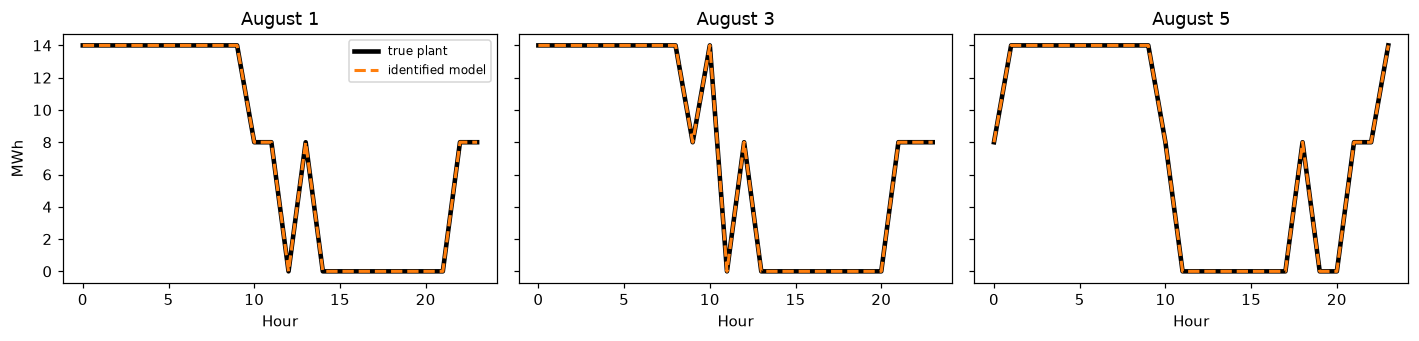

In [4]:
test_prices = fx.load_prices("2022-08").to_numpy()[:5] / 1000
actual, predicted = simulate(true, test_prices), simulate(theta, test_prices)
print(f"test nRMSE: {100 * nrmse(predicted, actual):.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, d in zip(axes, [0, 2, 4]):
    ax.plot(actual[d], "k", lw=3, label="true plant")
    ax.plot(predicted[d], "--", color="tab:orange", lw=2, label="identified model")
    ax.set(title=f"August {d + 1}", xlabel="Hour")
axes[0].set_ylabel("MWh"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**What the identified model does, machine by machine.** The meter only shows the total load. The identified model also explains *how* that load arises. Machine 1 can process 3 units/h but machine 2 only 2, so machine 1 runs ahead in cheap hours and fills the intermediate buffer, and machine 2 drains it later:

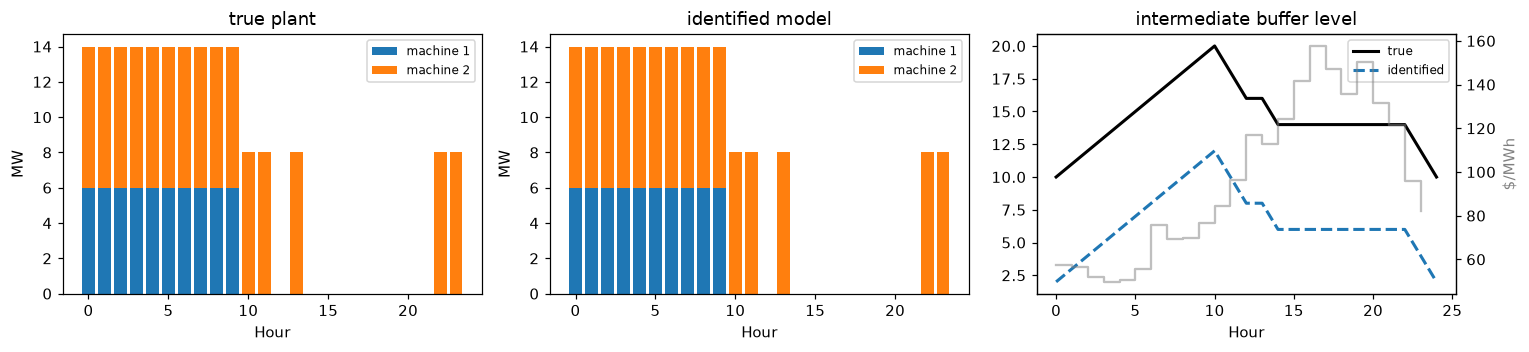

In [5]:
from indflex.identify import build_mstn

def machine_schedule(params, price):
    mm = build_mstn(params, price)
    fx.solve(mm)
    P = np.array([[mm.plant.P[t, i]() for i in range(2)] for t in range(24)])
    S = np.array([mm.plant.S[t, 1]() for t in range(25)])  # intermediate buffer
    return P, S

price = test_prices[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for ax, (label, params) in zip(axes[:2], [("true plant", true), ("identified model", theta)]):
    P, _ = machine_schedule(params, price)
    ax.bar(range(24), P[:, 0], label="machine 1", color="tab:blue")
    ax.bar(range(24), P[:, 1], bottom=P[:, 0], label="machine 2", color="tab:orange")
    ax.set(title=label, xlabel="Hour", ylabel="MW"); ax.legend(fontsize=8)
for label, params, style in [("true", true, "k-"), ("identified", theta, "--")]:
    axes[2].plot(machine_schedule(params, price)[1], style, lw=2, label=label)
axes[2].set(title="intermediate buffer level", xlabel="Hour"); axes[2].legend(fontsize=8)
ax2 = axes[2].twinx(); ax2.step(range(24), price * 1000, where="post", color="grey", alpha=0.5); ax2.set_ylabel("$/MWh", color="grey")
plt.tight_layout(); plt.show()

The identified model runs the same machines at the same hours, and its buffer follows the same pattern, only shifted: the meter data reveals how much the buffer *changes*, not its absolute level. That shift is the unidentifiable part noted above, and it does not change the load.

**Using the model: a demand-response event.** This is the use case in the thesis (Ch. 3, Fig. "Use cases for load modeling"). Before an event, an aggregator asks how the plant would respond if 06:00–11:00 became expensive. The identified model gives both the *baseline* (no event) and the *response*:

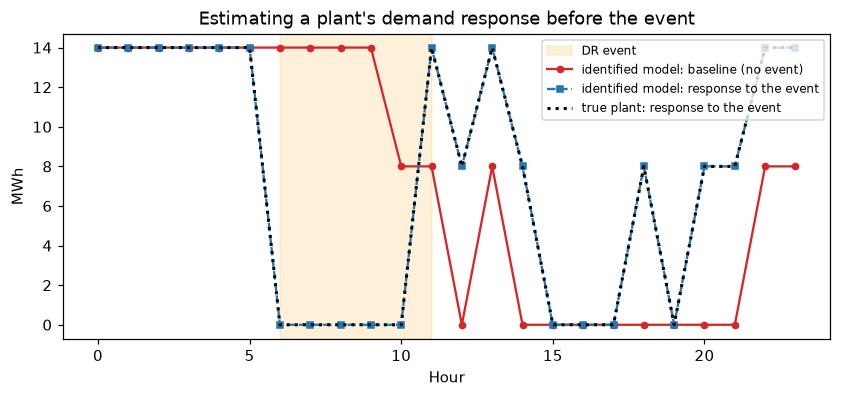

In [6]:
base = test_prices[0]
event = base.copy(); event[6:11] = 0.3  # $/kWh during the event
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(6, 11, color="orange", alpha=0.15, label="DR event")
ax.plot(simulate(theta, base[None])[0], "o-", color="tab:red", ms=4, label="identified model: baseline (no event)")
ax.plot(simulate(theta, event[None])[0], "s--", color="tab:blue", ms=4, label="identified model: response to the event")
ax.plot(simulate(true, event[None])[0], "k:", lw=2, label="true plant: response to the event")
ax.set(xlabel="Hour", ylabel="MWh", title="Estimating a plant's demand response before the event")
ax.legend(fontsize=8, loc="upper right"); plt.show()

## 4. When is iteration needed?

With many days of data, or a larger plant, two things change:

* **Solving all days at once is too large.** Each day adds its own primal and dual variables and its own bilinear constraint.
* **A single day can mislead.** Some days can be explained by the wrong parameters (for example, swapping which machine is large).

PSI therefore iterates: it solves one day at a time under a short time limit, and after a first pass it also penalizes the distance from θ to the average of recent estimates, until the estimates agree across days (a zeroth-order stochastic method). Set `RUN_ITERATIVE = True` to watch this on the same plant (about 30 s). Each point is the solution of one day's inverse problem, not an initial guess.

In [7]:
RUN_ITERATIVE = False

if RUN_ITERATIVE:
    theta_it, hist = train_psi(true.g, prices, meter, n_iter=33, time_limit=1.0)
    pm = np.array([h.p_max for h in hist.theta])
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for i in range(2):
        ax.plot(pm[:, i], marker="o", ms=3, label=f"machine {i + 1} (true {true.p_max[i]:g} MW)")
        ax.axhline(true.p_max[i], color=f"C{i}", ls=":", lw=1)
    ax.axvline(len(prices), color="grey", ls="--", lw=1)
    ax.text(len(prices) + 0.3, ax.get_ylim()[1] * 0.92, "consensus penalty on", fontsize=8, color="grey")
    ax.set(xlabel="Iteration (= one day's inverse problem)", ylabel="Rated power (MW)",
           title="Identified rated powers over the iterations"); ax.legend(fontsize=8, loc="center right")
    plt.show()

## 5. Optional: a real plant (cement, 4 stages)

The paper applies PSI to plants simulated with the STNs of notebook 01, whose on/off machines the mSTN can only approximate. This is much harder to solve. The paper's runs give Gurobi 120 s per iteration for about 210 iterations (hours of solver time) and reach 5.2% error on the cement plant. With 1 s per iteration, the solver often stops at a trivial "produce nothing" model. A prior from public data avoids that: every unit of product passes every machine, so the daily production target is about *daily energy* $/\sum_i 1/g_i$. Set `RUN_CEMENT = True` to try it (about 45 s; we saw 13–14% error).

In [8]:
RUN_CEMENT = False

if RUN_CEMENT:
    from indflex.identify import make_meter_dataset
    from indflex.identify.psi import target_from_energy
    ds = make_meter_dataset(fx.load_plant("cement_golmohamadi2020"))
    g = np.array([1000 / 2200, 250 / 11000, 300 / 11550, 350 / 11220])
    target = target_from_energy(g, ds.load_train)
    th, h = train_psi(g, ds.price_train, ds.load_train, n_iter=43, target_bounds=(target, target))
    print(f"{h.seconds:.0f} s, test nRMSE {100 * nrmse(simulate(th, ds.price_test), ds.load_test):.1f}%")

**Takeaways**
* PSI fits a *structured* model: the factory's optimal response under process constraints, not a free-form curve. Inverse optimization turns "the schedule must be optimal" into constraints, and the private parameters become decision variables.
* Strong duality makes the problem nonconvex. A small plant needs one solve; with many days or larger plants, PSI cycles through the days and averages the estimates, which keeps each solve small.
* Parameters the data never exercise (such as a buffer that never fills) cannot be identified, but they also do not change the predicted response.
* Next in the chain: thousands of such models are too complex for a grid model, so we compress them → **notebook 04: dimension reduction (D3R)**.